**CS1090A Final Project · Group 77**

**Members:** Daniel Wang, Russell Luo, Tae Jun Cha, Aviel Eng, Eric Huang

# Milestone 3 — EDA, Baseline Models and Hidden Gems

Starts from the cleaned table built in `milestone2_data.ipynb` (`clean/player_seasons.parquet`, one row per player per season).

**Questions**

1. **What drives market value?** EDA on the target and its main correlates.
2. **How well can we predict it?** Time-based split; models **with and without** last season's value.
3. **Which factors matter most?** Coefficients and permutation importance.
4. **Hidden gems.** (a) players valued below what their stats suggest; (b) players predicted to rise in value next season, backtested on past seasons.


### Key findings (details and interpretation in each section)

1. **What drives value:** league (Premier League median €8m vs €0.35–0.4m in Scotland, Denmark, Greece and Ukraine), age (inverted U peaking around 27), and playing time. Goals and assists add little once these are known.
2. **Prediction:** from stats alone, boosting reaches **R² = 0.83 on the 2025 test season**, with a typical miss of ×1.5. Adding last season's value gives R² ≈ 0.93 (×1.25).
3. **Hidden gems:** the "undervalued by stats" signal works only at the extreme and is noisy. A direct next-season growth model (R² ≈ 0.28) gives a believable shortlist of young starters in the Eredivisie, Denmark and Portugal. Players flagged by **both** signals are the best leads.


## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")
RNG = 109

/Users/dwang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
df = pd.read_parquet(Path("clean") / "player_seasons.parquet")
assert not df.duplicated(["player_id", "season"]).any()
print(df.shape)
df.head()

(85721, 40)


,player_id,season,n_apps,goals,assists,minutes_played,yellow_cards,red_cards,league_apps,league_minutes,league_goals,league_assists,intl_apps,intl_minutes,club_id,n_clubs,club_name,domestic_competition_id,league,season_end,value_date,market_value_eur,name,date_of_birth,position,sub_position,foot,height_in_cm,country_of_citizenship,age,goals_per90,assists_per90,minutes_per_app,played_europe,log_market_value,prev_market_value_eur,prev_minutes,prev_goals,next_market_value_eur,log_value_growth
0,10,2012,36,16,3,2585,8,0,29.000,"2,186.000",15.000,3.000,0.000,0.000,398,1,Società Sportiva Lazio S.p.A.,IT1,Italy: serie-a,2013-06-30,2013-06-19,"2,000,000.000",Miroslav Klose,1978-06-09,Attack,Centre-Forward,right,184.000,Germany,35.058,0.557,0.104,71.806,0,6.301,"6,000,000.000",NaN,NaN,"1,000,000.000",-0.301
1,86175,2012,32,4,11,2616,2,0,31.000,"2,559.000",4.000,11.000,0.000,0.000,4,1,1.FC Nuremberg,L1,Germany: bundesliga,2013-06-30,2013-06-30,"6,000,000.000",Hiroshi Kiyotake,1989-11-12,Midfield,Attacking Midfield,right,172.000,Japan,23.630,0.138,0.378,81.750,0,6.778,"2,250,000.000",NaN,NaN,"7,000,000.000",0.067
2,86172,2012,4,0,0,97,1,0,4.000,97.000,0.000,0.000,0.000,0.000,4,1,1.FC Nuremberg,L1,Germany: bundesliga,2013-06-30,2013-06-30,"900,000.000",Mu Kanazaki,1989-02-16,Attack,Centre-Forward,right,182.000,Japan,24.367,0.000,0.000,24.250,0,5.954,"1,200,000.000",NaN,NaN,NaN,NaN
3,170472,2012,15,0,0,795,3,0,15.000,795.000,0.000,0.000,0.000,0.000,273,1,Stade Rennais FC,FR1,France: ligue-1,2013-06-30,2013-05-30,"1,000,000.000",Dimitri Foulquier,1993-03-23,Defender,Right-Back,right,183.000,Guadeloupe,20.271,0.000,0.000,53.000,0,6.000,"300,000.000",NaN,NaN,"1,500,000.000",0.176
4,43259,2012,35,3,2,1150,1,0,30.000,"1,019.000",3.000,1.000,0.000,0.000,1519,1,Dundee United FC,SC1,Scotland: scottish-premiership,2013-06-30,2013-02-14,"250,000.000",Michael Gardyne,1986-01-23,Attack,Left Winger,both,171.000,Scotland,27.433,0.235,0.157,32.857,0,5.398,NaN,NaN,NaN,"250,000.000",0.000


**Reminders from Milestone 2**

* `season` is the starting year (`2023` = 2023/24). `market_value_eur` is read at 30 June at the end of the season.
* `log_market_value` is **log10** of the value, and `log_value_growth` = log10(next / current). So a growth of 0.3 ≈ ×2.
* `next_market_value_eur` / `log_value_growth` are **targets only, never features**. They are missing for 2025 (the future hasn't happened yet).

## 1. EDA — what drives market value?

### 1.1 The target

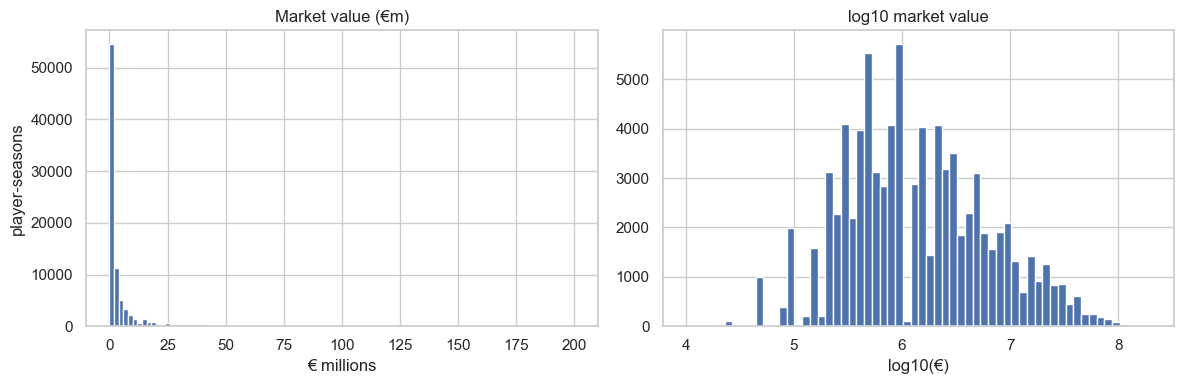

count        85,721.000
mean      4,645,224.391
std      10,352,624.626
min          10,000.000
10%         225,000.000
25%         450,000.000
50%       1,200,000.000
75%       4,000,000.000
90%      12,000,000.000
99%      50,000,000.000
max     200,000,000.000
Name: market_value_eur, dtype: float64

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["market_value_eur"] / 1e6, bins=100)
ax[0].set(title="Market value (€m)", xlabel="€ millions", ylabel="player-seasons")
ax[1].hist(df["log_market_value"], bins=60)
ax[1].set(title="log10 market value", xlabel="log10(€)")
plt.tight_layout(); plt.show()
df["market_value_eur"].describe(percentiles=[.1, .25, .5, .75, .9, .99])

> **Interpretation.** Raw values are extremely right-skewed (skewness ≈ 5.9): the median player-season is worth **€1.2m**, but the top 1% are above €50m and the maximum is €200m. On a log10 scale the distribution is close to symmetric (skewness ≈ 0.3).
> 
> **Consequence:** we model `log_market_value`. Errors then mean *"off by a factor of X"* rather than *"off by €X"*. That is the right scale here, because a €2m miss is huge for a €500k player and trivial for an €80m one.

### 1.2 Age

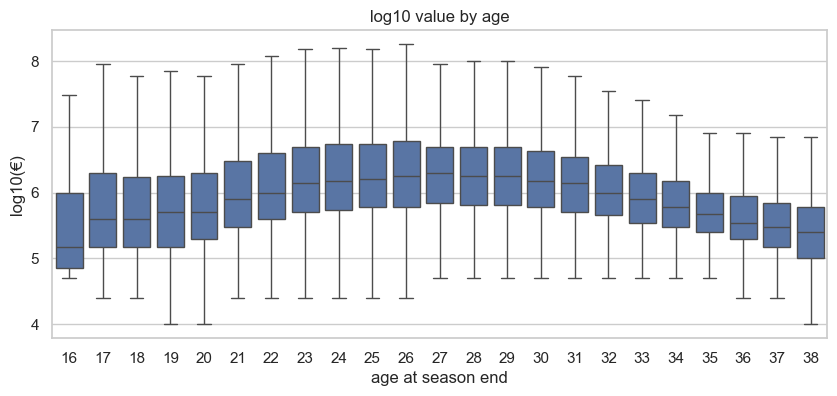

In [4]:
age_bin = df["age"].clip(16, 38).round()
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=age_bin.astype(int), y=df["log_market_value"], ax=ax, showfliers=False)
ax.set(title="log10 value by age", xlabel="age at season end", ylabel="log10(€)")
plt.show()

> **Interpretation.** Value follows a clear **inverted U** with age. The median rises from about €0.5m at 19–20 to a peak of **€2.0m at 27**, then falls to €1.0m by 32 and €0.35m by 36.
> 
> This explains why `age` has almost **zero linear correlation** with value (r ≈ −0.03, Section 1.5) even though it is one of the most important features. The relationship is strong but not a straight line. That is why the linear model gets an `age_sq` term and why tree models do well here.

### 1.3 League and position

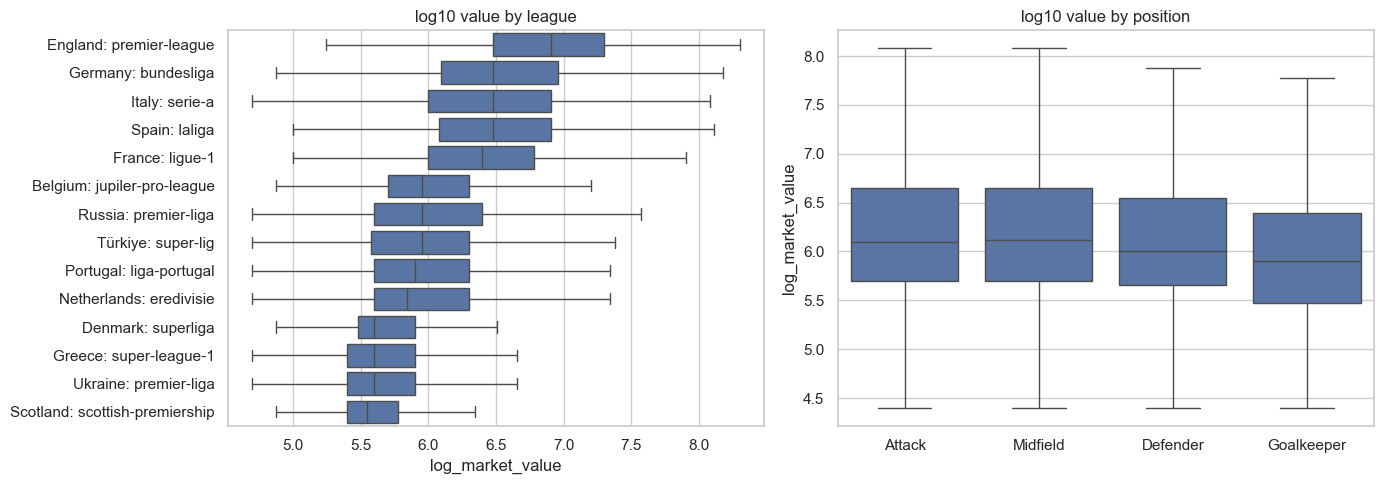

In [5]:
order = df.groupby("league")["log_market_value"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, y="league", x="log_market_value", order=order, ax=ax[0], showfliers=False)
ax[0].set(title="log10 value by league", ylabel="")
sns.boxplot(data=df, x="position", y="log_market_value", ax=ax[1], showfliers=False)
ax[1].set(title="log10 value by position", xlabel="")
plt.tight_layout(); plt.show()

> **Interpretation.** **League is the single biggest split in the data.** Median value by league:
> 
> * **Premier League:** €8.0m, about 3× any other league.
> * **LaLiga, Serie A, Bundesliga:** €3.0m. **Ligue 1:** €2.5m.
> * **Turkey, Russia, Belgium, Portugal, Netherlands:** €0.7–0.9m.
> * **Ukraine, Greece, Denmark, Scotland:** €0.35–0.4m.
> 
> So the same player profile is priced very differently depending on where they play. Part of that is real quality, and part is the money in each league.
> 
> **Position matters much less.** Medians are €1.3m for midfielders, €1.25m for attackers, €1.0m for defenders and €0.8m for goalkeepers. Goalkeepers are cheaper because only one plays per team, so most goalkeeper-seasons belong to backups.

### 1.4 Playing time and output

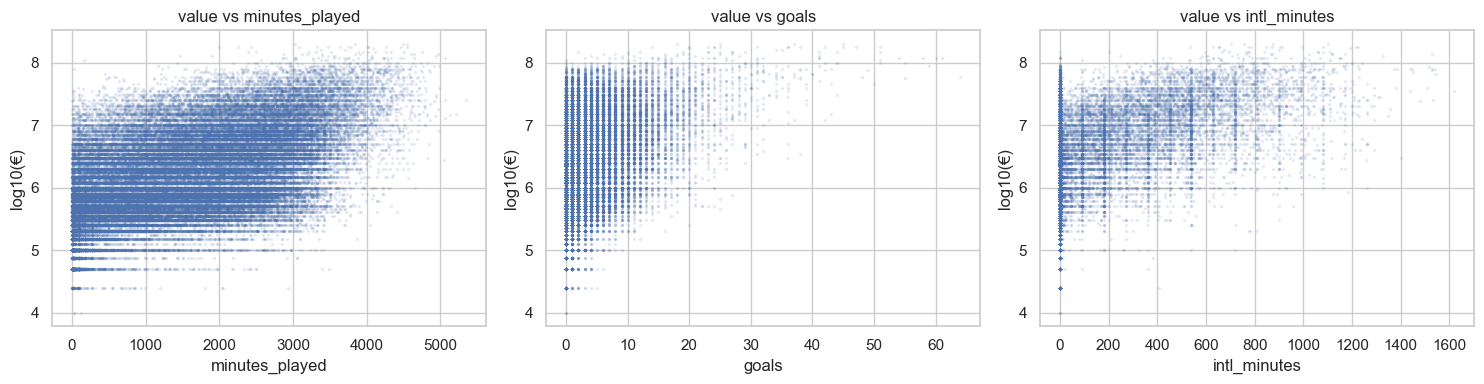

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["minutes_played", "goals", "intl_minutes"]):
    a.scatter(df[col], df["log_market_value"], s=2, alpha=0.1)
    a.set(xlabel=col, ylabel="log10(€)", title=f"value vs {col}")
plt.tight_layout(); plt.show()

> **Interpretation.** **Playing time is the strongest performance signal.** Median value by minutes played in the season:
> 
> | minutes | median value |
> |---|---|
> | 0–500 | €0.4m |
> | 500–1,500 | €1.0m |
> | 1,500–2,500 | €2.0m |
> | 2,500+ | €5.0m |
> 
> The causation runs both ways: good players get minutes, and clubs give minutes to expensive players. Goals add something on top, but the cloud is wide because defenders score little regardless of value. **European minutes are a strong marker of quality.** Players who appeared in a UEFA competition have a median value of **€8m vs €1m** for those who didn't, because only the best clubs in each league qualify.

### 1.5 Correlations with log value

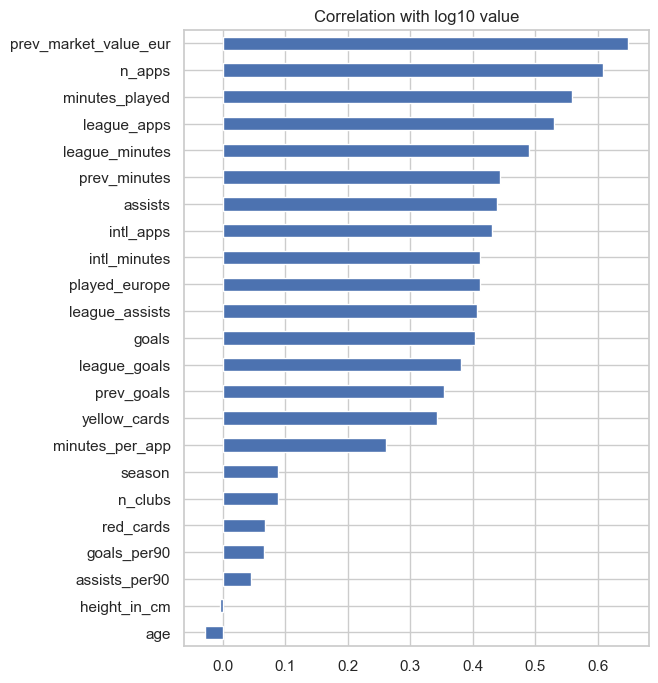

In [7]:
num_cols = df.select_dtypes("number").columns.drop(
    ["player_id", "club_id", "market_value_eur", "log_market_value",
     "next_market_value_eur", "log_value_growth"])
corr = df[num_cols].corrwith(df["log_market_value"]).sort_values()
corr.plot.barh(figsize=(6, 8), title="Correlation with log10 value"); plt.show()

> **Interpretation.** * **Strongest:** last season's value (r = 0.90 on the log scale), then appearances (0.61), minutes (0.56), league appearances and minutes (~0.5), and European games (~0.42).
> * **Rate stats are weak.** Goals and assists per 90 have r < 0.1: they are noisy for low-minute players and meaningless for defenders. Season *totals* (which mix in playing time) correlate far better.
> * **`age` is near zero** because of the inverted U (1.2), and **`yellow_cards` at 0.34** is a stand-in for minutes, not a sign that clubs value aggression.
> * Many count features are near-duplicates (`n_apps` vs `league_apps`, `minutes_played` vs `league_minutes`). That collinearity matters when reading linear coefficients in Section 4.2.
> 
> **EDA takeaway:** value is driven mainly by **where** a player plays (league, European football), **how much** he plays, and **how old** he is. Scoring output is secondary, and last season's value is close to a summary of all of these.

## 2. Modeling setup

### 2.1 Time-based split
The same player appears in many seasons, so a random split would leak. We split by season:

| set | seasons | use |
|---|---|---|
| train | 2012–2023 | fit |
| validation | 2024 | tune / pick model |
| test | 2025 | report once, at the end |

In [8]:
TRAIN = df["season"] <= 2023
VAL   = df["season"] == 2024
TEST  = df["season"] == 2025
print({k: int(m.sum()) for k, m in [("train", TRAIN), ("val", VAL), ("test", TEST)]})

{'train': 73169, 'val': 6241, 'test': 6311}


> **Interpretation.** Each validation and test season holds about 6,200–6,300 player-seasons, enough for stable metrics. Training uses 12 seasons (73k rows). Because every evaluation season comes **after** all training seasons, the scores tell us how well the model predicts the future, which is how it would actually be used.

### 2.2 Features
Everything is measured during or before the season. Snapshot columns from `players` (current club, caps, highest value) were already excluded in Milestone 2.

In [9]:
TARGET = "log_market_value"

NUM = ["age", "height_in_cm",
       "n_apps", "minutes_played", "goals", "assists", "yellow_cards", "red_cards",
       "league_apps", "league_minutes", "league_goals", "league_assists",
       "intl_apps", "intl_minutes", "goals_per90", "assists_per90", "minutes_per_app",
       "played_europe", "n_clubs", "season",
       "prev_minutes", "prev_goals"]
CAT = ["league", "position", "sub_position", "foot"]
PREV = ["log_prev_value"]   # the "history" feature we toggle on/off

df["log_prev_value"] = np.log10(df["prev_market_value_eur"])
df["age_sq"] = (df["age"] - 26) ** 2       # lets the linear model bend around the peak age
NUM_LIN = NUM + ["age_sq"]

def feats(with_prev, linear=False):
    num = (NUM_LIN if linear else NUM) + (PREV if with_prev else [])
    return num, CAT

### 2.3 Model pipelines

In [10]:
def make_ridge(num, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])
    return Pipeline([("pre", pre), ("model", Ridge(alpha=1.0))])

def make_hgb(num, cat):
    # Trees handle NaN natively; categoricals are ordinal-encoded and flagged as categorical.
    pre = ColumnTransformer([
        ("num", "passthrough", num),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                               encoded_missing_value=-1), cat),
    ])
    is_cat = [False] * len(num) + [True] * len(cat)
    model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31,
                                          categorical_features=is_cat, random_state=RNG)
    return Pipeline([("pre", pre), ("model", model)])

def evaluate(pipe, num, cat, train=TRAIN, val=VAL, target=TARGET):
    tr = df[train].dropna(subset=[target]); va = df[val].dropna(subset=[target])
    pipe.fit(tr[num + cat], tr[target])
    pred = pipe.predict(va[num + cat])
    return {"R2": r2_score(va[target], pred),
            "MAE (log10)": mean_absolute_error(va[target], pred),
            # median ratio error: 10**MAE ≈ typical multiplicative miss
            "median |ratio| miss": 10 ** np.median(np.abs(va[target] - pred))}

## 3. Baselines and main models (validated on 2024)

* **Naive baselines:** league × position median; "same as last season".
* **Ridge** and **gradient boosting**, each **without** and **with** last season's value.

In [11]:
tr, va = df[TRAIN], df[VAL]
rows = {}

med = tr.groupby(["league", "position"])[TARGET].median()
p = va.join(med.rename("p"), on=["league", "position"])["p"].fillna(tr[TARGET].median())
rows["league×position median"] = {"R2": r2_score(va[TARGET], p), "MAE (log10)": mean_absolute_error(va[TARGET], p),
                                  "median |ratio| miss": 10 ** np.median(np.abs(va[TARGET] - p))}

m = va["log_prev_value"].notna()
p = va.loc[m, "log_prev_value"]
rows["last season's value (rows with one)"] = {"R2": r2_score(va.loc[m, TARGET], p),
    "MAE (log10)": mean_absolute_error(va.loc[m, TARGET], p),
    "median |ratio| miss": 10 ** np.median(np.abs(va.loc[m, TARGET] - p))}

models = {}
for with_prev in [False, True]:
    tag = "with prev" if with_prev else "stats only"
    num, cat = feats(with_prev, linear=True)
    models[f"ridge, {tag}"] = (make_ridge(num, cat), num, cat)
    num, cat = feats(with_prev)
    models[f"boosting, {tag}"] = (make_hgb(num, cat), num, cat)

for name, (pipe, num, cat) in models.items():
    rows[name] = evaluate(pipe, num, cat)

results = pd.DataFrame(rows).T
results

,R2,MAE (log10),median |ratio| miss
league×position median,0.279,0.471,2.500
last season's value (rows with one),0.789,0.216,1.429
"ridge, stats only",0.739,0.283,1.710
"boosting, stats only",0.818,0.230,1.503
"ridge, with prev",0.877,0.178,1.357
"boosting, with prev",0.927,0.134,1.251


> **Interpretation.** How to read the columns:
> 
> * **R²:** share of the variance in log value explained.
> * **MAE (log10):** average error in log units.
> * **Median |ratio| miss:** the typical prediction is off by this *factor*, high or low. ×1.5 means a €2m player is typically predicted somewhere between €1.33m and €3m.
> 
> Results on 2024:
> 
> 1. **League × position alone** gets R² = 0.28 with a typical miss of ×2.5. League matters, but it leaves most of the variation unexplained.
> 2. **"Same as last season"** is a strong naive baseline (R² = 0.79, ×1.43). Transfermarkt values move slowly.
> 3. **Stats only:** boosting (R² = **0.82**, ×1.50) clearly beats ridge (0.74, ×1.71). The gain comes from non-linear effects like the age curve and from league × playing-time interactions. Note that boosting on stats alone **beats "same as last season" on R²**, so performance data carries real information.
> 4. **With last season's value:** boosting reaches R² = **0.93** with a typical miss of only ×1.25. Most of that gain comes from the history feature, not the stats.
> 
> **Which to use depends on the question.** For *"what is a player worth?"* the with-history model is best. For *"who is mispriced?"* (Section 5) we must use the **stats-only** model. The with-history model mostly repeats Transfermarkt's previous opinion, so it cannot disagree with it.

## 4. Which factors matter most?

### 4.1 Permutation importance — boosting, stats only (validation set)

/Users/dwang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/dwang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/dwang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/dwang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
/Users/dwang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas require

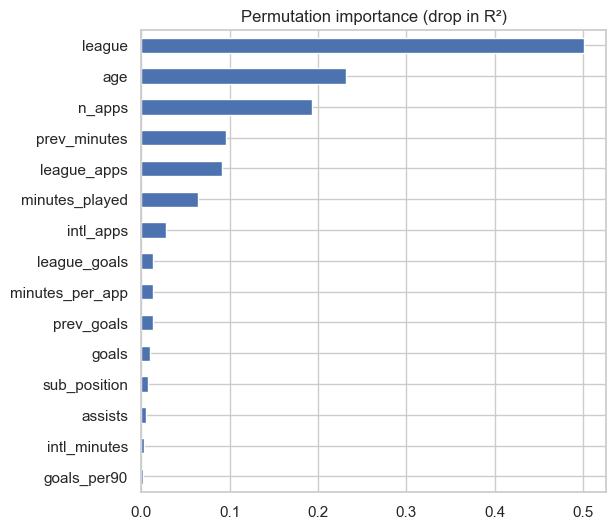

,drop in R²
league,0.501
age,0.232
n_apps,0.193
prev_minutes,0.096
league_apps,0.091
minutes_played,0.064
intl_apps,0.028
league_goals,0.013
minutes_per_app,0.013
prev_goals,0.013


In [12]:
pipe, num, cat = models["boosting, stats only"]
va = df[VAL].dropna(subset=[TARGET])
imp = permutation_importance(pipe, va[num + cat], va[TARGET], n_repeats=5,
                             random_state=RNG, scoring="r2", n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=num + cat).sort_values()
imp.tail(15).plot.barh(figsize=(6, 6), title="Permutation importance (drop in R²)"); plt.show()
imp.sort_values(ascending=False).head(10).to_frame("drop in R²")

> **Interpretation.** Permutation importance shuffles one feature at a time on the 2024 validation set and measures how much R² drops.
> 
> * **`league` dominates:** shuffling it costs **0.50 R²**. This confirms the EDA: the same output is priced very differently by league.
> * **`age` is second (0.23).** The model uses the inverted U from 1.2, even though age has almost no linear correlation with value.
> * **Playing time comes next:** `n_apps` (0.19), last season's minutes (0.10), league appearances (0.09) and total minutes (0.06). Being a regular starter, this season and last, is the main performance signal.
> * **Goals, assists and per-90 rates barely matter** (≤ 0.013 each) once league, age and playing time are known. Transfermarkt values look more like *"a starter in a strong league at a good age"* than *"scores a lot"*.
> 
> Caveat: correlated features share credit. Shuffling `n_apps` alone understates the total value of playing time, because `league_apps` and `minutes_played` still carry most of the same information.

### 4.2 Ridge coefficients (standardised), stats only

In [13]:
pipe, num, cat = models["ridge, stats only"]
names = pipe.named_steps["pre"].get_feature_names_out()
coef = pd.Series(pipe.named_steps["model"].coef_, index=names)
coef.reindex(coef.abs().sort_values(ascending=False).index).head(20).to_frame("coef")

,coef
cat__league_England: premier-league,0.607
num__n_apps,0.534
cat__league_Scotland: scottish-premiership,-0.455
cat__league_Denmark: superliga,-0.378
cat__league_Italy: serie-a,0.334
cat__league_Germany: bundesliga,0.327
num__league_apps,-0.323
cat__league_Greece: super-league-1,-0.317
cat__league_France: ligue-1,0.291
cat__league_Spain: laliga,0.289


> **Interpretation.** Features are standardised, so a coefficient is the change in **log10 value** per standard deviation (numeric features) or relative to the average league (league dummies). A coefficient of 0.3 ≈ ×2.
> 
> * **League effects are large and agree with the boxplots.** The Premier League is +0.61 (≈ ×4 vs. an average league). Scotland (−0.46), Denmark (−0.38), Greece and Ukraine are at the bottom.
> * **Do not read the playing-time signs one by one.** `n_apps` is +0.53 but `league_apps` is −0.32, and `minutes_played` is −0.15 but `league_minutes` is +0.12. These pairs are highly correlated, so ridge splits their effect in arbitrary-looking ways. Their **combined** effect is clearly positive. To interpret them separately, drop one of each pair or use PCA.
> * `age_sq` is negative (−0.12), which confirms the inverted U. Value falls off on both sides of 26.
> 
> **Overall:** the linear and tree models agree on the story (league, age, playing time). The permutation importances in 4.1 are the more trustworthy *ranking*.

## 5. Hidden gems

### 5.1 Undervalued right now
Fit the **stats-only** model and look at players whose predicted value is well above their actual value: they're producing like more expensive players. Out-of-sample: train on seasons before the one we score.

In [14]:
def score_season(season, min_minutes=1500, max_age=23):
    num, cat = feats(with_prev=False)
    tr = df[df["season"] < season]
    sc = df[df["season"] == season].copy()
    pipe = make_hgb(num, cat).fit(tr[num + cat], tr[TARGET])
    sc["pred_log"] = pipe.predict(sc[num + cat])
    sc["undervaluation"] = sc["pred_log"] - sc[TARGET]   # >0: worth more than valued; 0.3 ≈ ×2
    sc["predicted_value_eur"] = 10 ** sc["pred_log"]
    return sc[(sc["minutes_played"] >= min_minutes) & (sc["age"] <= max_age)]

gems_2025 = score_season(2025)
show = ["name", "age", "position", "club_name", "league", "minutes_played", "goals", "assists",
        "market_value_eur", "predicted_value_eur", "undervaluation"]
gems_2025.sort_values("undervaluation", ascending=False)[show].head(25)

,name,age,position,club_name,league,minutes_played,goals,assists,market_value_eur,predicted_value_eur,undervaluation
80789,Jerry Afriyie,19.554,Attack,RAAL La Louvière,Belgium: jupiler-pro-league,2499,5,1,"1,200,000.000","9,342,126.709",0.891
81700,Oluwaseun Adewumi,21.347,Midfield,Cercle Brugge,Belgium: jupiler-pro-league,1585,5,0,"800,000.000","3,890,222.167",0.687
80267,Miguel Freckleton,22.899,Defender,St. Mirren FC,Scotland: scottish-premiership,3330,4,1,"200,000.000","912,939.370",0.659
85675,Nils Rossen,21.911,Midfield,SC Telstar,Netherlands: eredivisie,2755,3,2,"700,000.000","3,107,398.676",0.647
81254,Luc De Fougerolles,20.715,Defender,FCV Dender EH,Belgium: jupiler-pro-league,1906,0,1,"1,000,000.000","4,374,408.771",0.641
82990,Yannick Cappelle,22.982,Defender,Zulte Waregem,Belgium: jupiler-pro-league,2016,1,1,"650,000.000","2,209,776.644",0.531
79479,Jakob Napoleon Romsaas,22.122,Midfield,Royal Charleroi Sporting Club,Belgium: jupiler-pro-league,1919,2,4,"1,200,000.000","3,769,654.417",0.497
80578,Juanse Rodríguez,20.260,Midfield,CD Tondela,Portugal: liga-portugal,2007,0,0,"1,000,000.000","3,107,793.922",0.492
81086,Precious Ugwu,20.389,Defender,FC Volendam,Netherlands: eredivisie,2528,0,0,"500,000.000","1,548,306.404",0.491
84761,Arthur Piedfort,21.407,Midfield,KVC Westerlo,Belgium: jupiler-pro-league,2992,3,3,"4,000,000.000","11,825,115.988",0.471


> **Interpretation.** This lists players aged 23 or under with 1,500+ minutes in 2025/26 whose stats-only prediction is far above their Transfermarkt value. `undervaluation` is on the log10 scale: **0.3 ≈ ×2, 0.6 ≈ ×4, 0.9 ≈ ×8.**
> 
> * The list is dominated by **Belgium, the Netherlands, Scotland and Portugal**: young regular starters in mid-tier leagues, often at small clubs (La Louvière, Dender, Telstar, St. Mirren).
> * The top case, Jerry Afriyie, is valued at €1.2m vs. a predicted €9.3m (×8).
> 
> **Be careful with these flags.** The model sees league, age and minutes, but not things like contract length, injury history, release clauses or the quality of the club around the player. A big gap can mean *"the market is missing this player"*, but it can also mean *"the model is missing information"*. Section 5.2 tests which one is more common.

### 5.2 Backtest: did "undervalued" players actually rise?
If the model finds real gems, players flagged in season *s* should gain more value by season *s+1* than similar players who weren't flagged.

In [15]:
bt = []
for s in [2020, 2021, 2022, 2023, 2024]:
    sc = score_season(s).dropna(subset=["log_value_growth"])
    sc["decile"] = pd.qcut(sc["undervaluation"], 10, labels=False, duplicates="drop")
    bt.append(sc.assign(scored_season=s))
bt = pd.concat(bt)
summary = bt.groupby("decile")["log_value_growth"].agg(["mean", "median", "size"])
summary["mean ×"] = 10 ** summary["mean"]
summary

,mean,median,size,mean ×
decile,,,,
0,0.099,0.079,185,1.257
1,0.076,0.058,184,1.192
2,0.090,0.067,184,1.230
3,0.087,0.049,184,1.221
4,0.065,0.028,184,1.161
5,0.064,0.000,184,1.159
6,0.008,0.000,183,1.018
7,0.088,0.046,185,1.225
8,0.053,0.000,183,1.129


> **Interpretation.** For seasons 2020–2024, we scored young regular starters with a model trained only on earlier seasons. We then grouped them into deciles by undervaluation and checked how their value changed the **following** season.
> 
> * **Every decile gains value on average** (×1.02 to ×1.39), because young starters tend to rise anyway. So the right comparison is *between* deciles, not against zero.
> * **The most-undervalued decile (9) gains the most:** a mean of ×1.39 and a median of ×1.25. That is the result we hoped for.
> * **But the signal is not monotonic.** The *least* undervalued decile (0) comes second (×1.26), and deciles 1–8 show no clear trend. If the model were simply right, growth would rise steadily from decile 0 to 9.
> 
> **Conclusion:** the stats-only gap has **some** predictive value at the extreme top, but it is noisy. Extreme negative gaps may also be meaningful: players valued well above their stats are often highly rated prospects whose value keeps climbing. As a scouting tool, treat the undervalued list as a **filter for further scouting, not a buy list**. This is a natural thing to improve in later milestones.

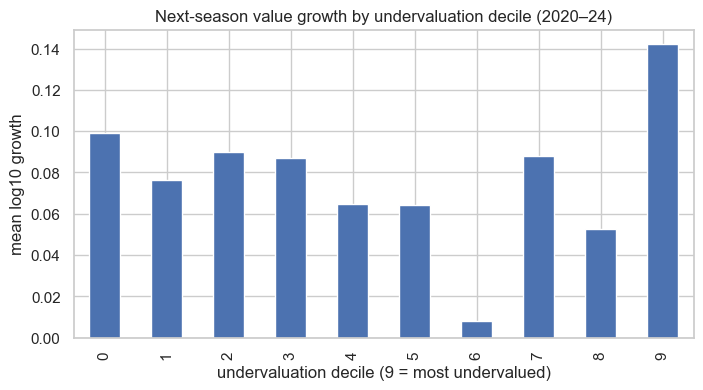

In [16]:
ax = summary["mean"].plot.bar(figsize=(8, 4), title="Next-season value growth by undervaluation decile (2020–24)")
ax.set(xlabel="undervaluation decile (9 = most undervalued)", ylabel="mean log10 growth"); plt.show()

### 5.3 Predicting next season's growth directly
Target: `log_value_growth`. Here last season's and this season's value **are** legitimate features (we know them at the end of the season). Train ≤ 2022, validate 2023, test 2024 (2025 has no future value yet).

In [17]:
GROWTH = "log_value_growth"
num_g = NUM + ["log_prev_value", TARGET]
gtrain, gval, gtest = df["season"] <= 2022, df["season"] == 2023, df["season"] == 2024

g_rows = {}
va = df[gval].dropna(subset=[GROWTH])
g_rows["predict zero growth"] = {"R2": r2_score(va[GROWTH], np.zeros(len(va))),
                                 "MAE (log10)": mean_absolute_error(va[GROWTH], np.zeros(len(va)))}
growth_model = make_hgb(num_g, CAT)
g_rows["boosting"] = evaluate(growth_model, num_g, CAT, train=gtrain, val=gval, target=GROWTH)
pd.DataFrame(g_rows).T

,R2,MAE (log10),median |ratio| miss
predict zero growth,-0.003,0.196,NaN
boosting,0.283,0.167,1.325


> **Interpretation.** Next-season growth is **much harder to predict** than the level of value:
> 
> * Predicting "no change" gives R² ≈ 0 (by construction).
> * The boosting model reaches **R² = 0.28** with a typical miss of ×1.33. It captures real structure: young players in cheap leagues tend to rise, and players past 30 tend to fall. But most of the year-to-year movement is unexplained, from transfers, breakout seasons and injuries the data can't see.
> 
> That is expected, not a failure. If next season's value were easy to predict from public stats, the market would already have priced it in. An R² of 0.28 on *changes* is a useful edge for ranking players, though not for exact forecasts.

### 5.4 Shortlist for a big club
Combine the signals and filter to what a big club would actually buy: young, regular starters, outside the top leagues (or cheap within them).

**TODO:** decide the filters as a group (age, minutes, budget, positions needed).

In [18]:
BIG5 = ["England: premier-league", "Spain: laliga", "Italy: serie-a",
        "Germany: bundesliga", "France: ligue-1"]

num_g = NUM + ["log_prev_value", TARGET]
fit = df[df["season"] <= 2024].dropna(subset=[GROWTH])
gm = make_hgb(num_g, CAT).fit(fit[num_g + CAT], fit[GROWTH])

short = gems_2025.copy()
short["pred_growth_x"] = 10 ** gm.predict(short[num_g + CAT])
short = short[~short["league"].isin(BIG5) & (short["market_value_eur"] <= 20e6)]
short.sort_values(["pred_growth_x"], ascending=False)[show + ["pred_growth_x"]].head(25)

,name,age,position,club_name,league,minutes_played,goals,assists,market_value_eur,predicted_value_eur,undervaluation,pred_growth_x
81008,Ruud Nijstad,18.450,Defender,FC Twente Enschede,Netherlands: eredivisie,1770,1,1,"10,000,000.000","3,544,787.988",-0.450,2.341
81664,Noah Markmann,19.346,Defender,FC Nordsjaelland,Denmark: superliga,1814,0,0,"2,500,000.000","2,077,129.802",-0.080,2.104
84265,Bernt Klaverboer,20.758,Goalkeeper,SC Heerenveen,Netherlands: eredivisie,2880,0,0,"3,000,000.000","1,968,205.555",-0.183,1.974
81488,Julius Berthel Askou,20.093,Defender,Odense Boldklub,Denmark: superliga,1633,0,0,"2,500,000.000","1,241,919.086",-0.304,1.886
80908,Nazar Domchak,19.233,Goalkeeper,Karpaty Lviv,Ukraine: premier-liga,2610,0,0,"4,000,000.000","1,077,932.584",-0.569,1.882
80808,Prince Amoako Junior,19.359,Attack,FC Nordsjaelland,Denmark: superliga,1896,7,5,"7,000,000.000","7,660,765.016",0.039,1.854
81086,Precious Ugwu,20.389,Defender,FC Volendam,Netherlands: eredivisie,2528,0,0,"500,000.000","1,548,306.404",0.491,1.829
84735,Dies Janse,20.449,Defender,FC Groningen,Netherlands: eredivisie,2814,2,2,"6,500,000.000","2,821,447.238",-0.362,1.825
81012,Ibrahima Ba,21.095,Defender,FC Famalicão,Portugal: liga-portugal,1655,1,1,"12,000,000.000","2,103,606.916",-0.756,1.758
80578,Juanse Rodríguez,20.260,Midfield,CD Tondela,Portugal: liga-portugal,2007,0,0,"1,000,000.000","3,107,793.922",0.492,1.750


> **Interpretation.** This shortlist uses the **growth model** trained on all seasons up to 2024. It keeps players aged 23 or under with 1,500+ minutes, outside the big five, and valued at €20m or less, ranked by predicted value multiple for next season.
> 
> * The top names are predicted to roughly **double** (×1.5 to ×2.3). Most are **18–21-year-old starters in the Eredivisie, the Danish Superliga and Liga Portugal**. These are leagues big clubs already scout and buy from, which suggests the model picks up a real pattern.
> * **The two gem signals often disagree.** Many players at the top of this list have a *negative* `undervaluation` (for example Ruud Nijstad at −0.45, Ibrahima Ba at −0.76). Transfermarkt already values them above what their stats alone suggest, yet the model still expects them to rise. This fits the 5.2 finding: highly rated prospects tend to *keep* rising.
> * **Players on both lists** (high `undervaluation` *and* high `pred_growth_x`, e.g. Precious Ugwu, Juanse Rodríguez, Miguel Freckleton, Luc De Fougerolles) are the strongest candidates. They look cheap for their output *and* are in a profile that historically gains value.
> 
> The growth-model shortlist has **not been backtested yet**. Before presenting it as a recommendation, repeat the 5.2 exercise for the growth model: score 2022 and 2023, then check the realised growth of the top 25.

## 6. Final test (run once)
After choosing the model on 2024 validation, refit on 2012–2024 and report on 2025.

In [19]:
FINAL = "boosting, stats only"   # best stats-only model on 2024 validation (Section 3)
_, num, cat = models[FINAL]
final_pipe = make_hgb(num, cat) if FINAL.startswith("boosting") else make_ridge(num, cat)
evaluate(final_pipe, num, cat, train=df["season"] <= 2024, val=TEST)

{'R2': 0.8281250907846696,
 'MAE (log10)': 0.22552381304394453,
 'median |ratio| miss': 1.5051568297628208}

> **Interpretation.** Refit on 2012–2024 and evaluated once on the untouched 2025/26 season, the stats-only boosting model scores **R² = 0.83, with a typical miss of ×1.51**. That is in line with its validation score (0.82, ×1.50), so the model **generalises to a new season without overfitting** to the validation set.
> 
> Bottom line for the project question: from public performance data, league and age alone, we can estimate a player's Transfermarkt value to within about ×1.5 for a typical player. League, age and playing time explain most of it. Last season's value narrows the miss to about ×1.25, and future *changes* in value are only modestly predictable (R² ≈ 0.28).

## 7. Caveats
* The target is Transfermarkt's crowd estimate, not transfer fees. A model trained on it partly learns Transfermarkt's biases, which is why the backtest (5.2) matters.
* Only 14 leagues are covered; players from untracked leagues are invisible.
* Survivorship: players who drop out of tracked leagues have no next-season value and leave the growth analysis.